# Movie Review Sentiment Analysis — Naive Bayes


In [1]:
%matplotlib inline
import sklearn
print('scikit-learn version:', sklearn.__version__)
assert sklearn.__version__ == '1.6.1', 'Install scikit-learn==1.6.1 and restart the runtime to match the frontend.'

scikit-learn version: 1.6.1


## 1. Import libraries

In [2]:
import pandas as pd, numpy as np, re, joblib, sklearn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
sns.set_style("whitegrid")

## 2. Load the dataset


In [3]:
# Colab upload/download UI; local execution uses the same CSV and writes files to disk.
try:
    from google.colab import files
except ImportError:
    from pathlib import Path
    class LocalFiles:
        @staticmethod
        def upload():
            if not Path("IMDB Dataset.csv").is_file():
                raise FileNotFoundError("Place IMDB Dataset.csv beside the notebook before running.")
            print("Using local IMDB Dataset.csv")
            return {}
        @staticmethod
        def download(filename):
            print("Saved:", filename)
    files = LocalFiles()
uploaded = files.upload()
df = pd.read_csv("IMDB Dataset.csv")
df.head()

Using local IMDB Dataset.csv


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 3. Exploratory Data Analysis (EDA)

### 3.1 Basic information

In [4]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate reviews:", df.duplicated().sum())
df.info()

Shape: (50000, 2)

Missing values:
 review       0
sentiment    0
dtype: int64

Duplicate reviews: 418
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [5]:
# Remove duplicate reviews
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (49582, 2)


### 3.2 Class balance
Checking if positive and negative reviews are equal in number.

sentiment
positive    24884
negative    24698
Name: count, dtype: int64


/workspace/scratch/ff7ada153b28/output/02_Naive_Bayes.ipynb:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  "nbformat": 4,


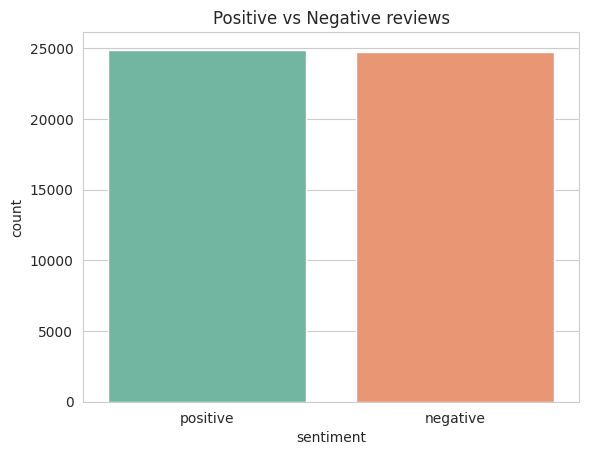

In [6]:
print(df["sentiment"].value_counts())
sns.countplot(x="sentiment", data=df, palette="Set2")
plt.title("Positive vs Negative reviews")
plt.show()

### 3.3 Review length
Do positive and negative reviews differ in length?

             count        mean         std   min    25%    50%    75%     max
sentiment                                                                    
negative   24698.0  229.596607  165.103430   4.0  128.0  174.0  278.0  1522.0
positive   24884.0  233.090620  177.688169  10.0  125.0  172.0  284.0  2470.0


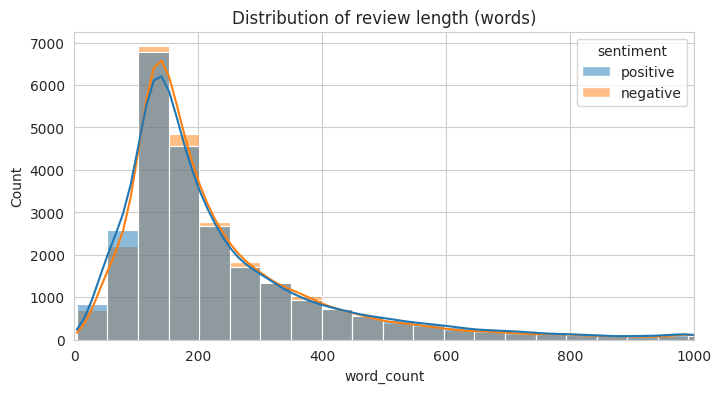

In [7]:
df["word_count"] = df["review"].apply(lambda x: len(x.split()))
print(df.groupby("sentiment")["word_count"].describe())

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="word_count", hue="sentiment", bins=50, kde=True)
plt.xlim(0, 1000)
plt.title("Distribution of review length (words)")
plt.show()

## 4. Text preprocessing
Remove HTML tags (like `<br />`) and convert to lowercase. Stopwords are removed later by TF-IDF.

In [8]:
def clean_text(text):
    text = re.sub(r"<.*?>", " ", text)
    return text.lower()

df["clean_review"] = df["review"].apply(clean_text)
df[["review", "clean_review"]].head(3)

,review,clean_review
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,a wonderful little production. the filming t...
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...


### 4.1 Word clouds
Most frequent words in positive and negative reviews.

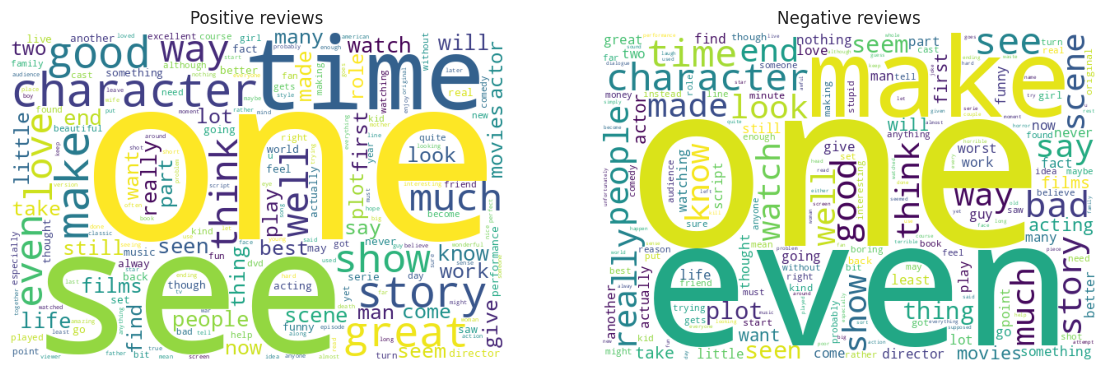

In [9]:
from wordcloud import WordCloud, STOPWORDS
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, label in enumerate(["positive", "negative"]):
    text = " ".join(df[df["sentiment"] == label]["clean_review"])
    wc = WordCloud(width=600, height=400, background_color="white",
                   stopwords=STOPWORDS.union({"br", "movie", "film"})).generate(text)
    ax[i].imshow(wc)
    ax[i].set_title(label.capitalize() + " reviews")
    ax[i].axis("off")
plt.show()

## 5. Feature extraction using TF-IDF
TF-IDF converts text into numbers. We split the data 80% train / 20% test.

In [10]:
y = (df["sentiment"] == "positive").astype(int)   # positive = 1, negative = 0
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"], y, test_size=0.2, random_state=42, stratify=y)

vec = TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)
print("Train shape:", Xtr.shape, " Test shape:", Xte.shape)

Train shape: (39665, 20000)  Test shape: (9917, 20000)


## Validation setup for the four individual experiments
The original 80/20 split and final TF-IDF matrices above remain unchanged. For tuning only, split the 80% training reviews again into 75% subtraining and 25% validation (60/20/20 overall). A separate vectorizer learns only from subtraining text. Select by validation accuracy, then refit the selected configuration on the original full 80% training matrix. Never choose settings using test results. The final exported models all use the original `vec`.

In [11]:
from sklearn.base import clone
from time import perf_counter
from IPython.display import display

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)
tuning_vec = clone(vec)
Xsub = tuning_vec.fit_transform(X_subtrain)
Xval = tuning_vec.transform(X_val)
models, preds, accs = {}, {}, {}
results, timing_results, experiment_tables = [], [], {}
selected_settings = {}
print('Subtraining:', Xsub.shape, 'Validation:', Xval.shape)
print('Final training:', Xtr.shape, 'Untouched test:', Xte.shape)

Subtraining: (29748, 20000) Validation: (9917, 20000)
Final training: (39665, 20000) Untouched test: (9917, 20000)


## Model 2: Naive Bayes
**Individual contribution:** baseline, three-setting validation experiment, training/validation graph, selected-model test evaluation, confusion matrix, and incorrect-review examples.

Probabilistic text classification; alpha controls additive smoothing.

The original setting is included among the candidates. Improvements are not guaranteed; interpret the measured results. Saved results come from the full-dataset execution; rerunning regenerates them.

In [12]:
model_name = 'Naive Bayes'
parameter_name = 'alpha'
candidate_values = [0.1, 0.5, 1.0]
baseline_value = 1.0

def make_candidate(value):
    return MultinomialNB(alpha=value)

trial_rows = []
for value in candidate_values:
    candidate = make_candidate(value)
    started = perf_counter()
    candidate.fit(Xsub, y_subtrain)
    elapsed = perf_counter() - started
    train_pred = candidate.predict(Xsub)
    val_pred = candidate.predict(Xval)
    trial_rows.append({
        parameter_name: value,
        'Training accuracy': accuracy_score(y_subtrain, train_pred),
        'Validation accuracy': accuracy_score(y_val, val_pred),
        'Validation F1': f1_score(y_val, val_pred),
        'Training seconds': elapsed,
        'Original setting': value == baseline_value
    })
trials = pd.DataFrame(trial_rows)
experiment_tables[model_name] = trials.copy()
display(trials.round(4))
# First candidate wins an exact tie; no test scores enter this decision.
best_index = int(np.argmax(trials['Validation accuracy'].to_numpy()))
best_value = candidate_values[best_index]
selected_settings[model_name] = {parameter_name: best_value}
print('Selected using validation accuracy:', selected_settings[model_name])

Selected using validation accuracy: {'alpha': 1.0}


,alpha,Training accuracy,Validation accuracy,Validation F1,Training seconds,Original setting
0,0.1,0.8969,0.8622,0.8643,0.0075,False
1,0.5,0.8947,0.8640,0.8662,0.0067,False
2,1.0,0.8929,0.8644,0.8663,0.0069,True


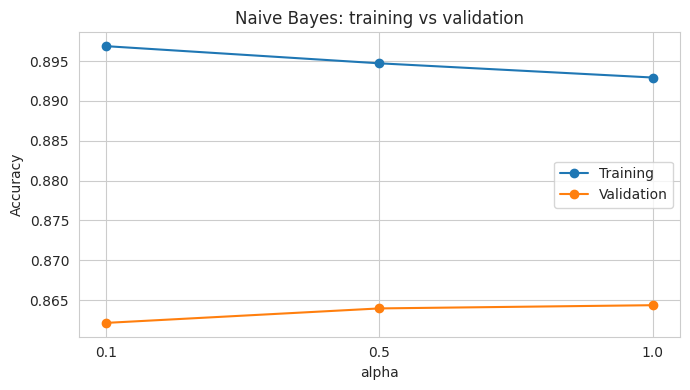

In [13]:
positions = np.arange(len(candidate_values))
plt.figure(figsize=(7, 4))
plt.plot(positions, trials['Training accuracy'], marker='o', label='Training')
plt.plot(positions, trials['Validation accuracy'], marker='o', label='Validation')
plt.xticks(positions, [str(v) for v in candidate_values])
plt.xlabel(parameter_name)
plt.ylabel('Accuracy')
plt.title(model_name + ': training vs validation')
plt.legend()
plt.tight_layout()
plt.show()

### Refit the selected configuration and evaluate once on the test set
Refitting uses the original full-training `Xtr` and its original vectorizer. Metrics below describe the selected model on held-out test reviews, not the tuning subset.

              precision    recall  f1-score   support

    Negative       0.88      0.86      0.87      4940
    Positive       0.86      0.88      0.87      4977

    accuracy                           0.87      9917
   macro avg       0.87      0.87      0.87      9917
weighted avg       0.87      0.87      0.87      9917



,Model,Accuracy,Precision,Recall,F1-score
0,Naive Bayes,0.8699,0.863,0.8807,0.8717


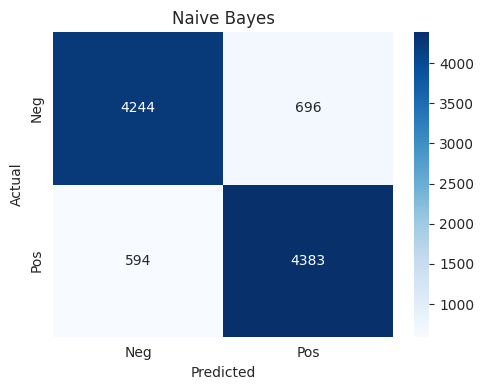

In [14]:
final_model = make_candidate(best_value)
started = perf_counter()
final_model.fit(Xtr, y_train)
fit_seconds = perf_counter() - started
started = perf_counter()
p = final_model.predict(Xte)
predict_seconds = perf_counter() - started
models[model_name] = final_model
preds[model_name] = p
accs[model_name] = round(accuracy_score(y_test, p), 4)
results.append([model_name, accuracy_score(y_test, p),
                precision_score(y_test, p), recall_score(y_test, p), f1_score(y_test, p)])
timing_results.append({'Model': model_name, 'Training seconds': fit_seconds,
                       'Test prediction seconds': predict_seconds})
display(pd.DataFrame([results[-1]], columns=[
    'Model', 'Accuracy', 'Precision', 'Recall', 'F1-score']).round(4))
print(classification_report(y_test, p, target_names=['Negative', 'Positive']))
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, p, labels=[0, 1]), annot=True, fmt='d',
            cmap='Blues', xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
plt.title(model_name)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

In [15]:
# Positional arrays avoid index alignment issues after the split.
error_table = pd.DataFrame({
    'Review': X_test.to_numpy(), 'Actual': y_test.to_numpy(), 'Predicted': p})
errors = error_table[error_table['Actual'] != error_table['Predicted']].copy()
errors['Actual'] = errors['Actual'].map({0: 'Negative', 1: 'Positive'})
errors['Predicted'] = errors['Predicted'].map({0: 'Negative', 1: 'Positive'})
print('Incorrect predictions:', len(errors), 'out of', len(y_test))
with pd.option_context('display.max_colwidth', 350):
    display(errors.head(5))

Incorrect predictions: 1290 out of 9917


,Review,Actual,Predicted
15,"this isn't exactly a great film, but i admire the writers and director for trying something a little different. the film's main theme is fate and small, seemingly insignificant things that can greatly change the future. in some ways this reminds me of the film sliding doors, though instead of focusing on one random event, seemingly random stuff...",Positive,Negative
24,"despite being a huge fan of fred astaire and ginger rogers' movies, it wasn't until about 6 years ago that i first saw 'follow the fleet'. i knew all the songs from an old astaire/rogers record (yes, vinyl) but knew nothing of the plot. unfortunately, while the songs are catchy and ginger rogers' character is sweet and funny, you just can't li...",Negative,Positive
43,"ok, let me again admit that i haven't seen any other merchant ivory (the distributor) films. nor have i seen more celebrated works by the director, so my capacity to discuss before the rains outside of analysis of the film itself is mitigated. with that admittance, let me begin. before the rains is a different kind of movie that doesn't know w...",Negative,Positive
45,"i'm not here to tell you ""armored"" is kubrickian, hitchcockian or fellini-esquire. nope. referenced directors are more like don siegel (""charlie varrick"") and walter hill (""the warriors""). those two helmers didn't fool around with niceties like putting women in their movies. no skirts need apply. they unapologetically made guy movies. guns, lot...",Positive,Negative
51,"this movie probably had a $750 budget, and still managed to surpass titanic. i rented this the day i crashed my mom's car, and it was the only thing that cheered me up beyond belief! it has to be tied with 'the assult of the killer bimbos'. things to look for are: 1. the drive in blow job chinese girl scene 2. the bleach blonde in the sassoon s...",Positive,Negative


### Explain your findings
After running, state: (1) which setting won on validation; (2) whether training and validation scores diverged; (3) final test metrics; (4) patterns you actually observe in the incorrect reviews. Do not claim an improvement or a cause of errors without evidence. Do not retune after reading test errors. Timing depends on the runtime hardware.

## Test your model on new reviews

In [16]:
def predict_review(text):
    X = vec.transform([clean_text(text)])
    return 'Positive' if models['Naive Bayes'].predict(X)[0] == 1 else 'Negative'

for text in ['This movie was absolutely fantastic, great acting!',
             'Terrible film. Boring and a complete waste of time.']:
    print(text, '->', predict_review(text))

This movie was absolutely fantastic, great acting! -> Positive
Terrible film. Boring and a complete waste of time. -> Negative


## Save this member’s self-contained model bundle
This bundle is for individual reuse. The integrated notebook alone exports the three frontend files.

In [17]:
bundle = {'model_name': 'Naive Bayes', 'model': models['Naive Bayes'],
          'vectorizer': vec, 'accuracy': accs['Naive Bayes'],
          'selected_settings': selected_settings['Naive Bayes'],
          'sklearn_version': sklearn.__version__}
joblib.dump(bundle, 'naive_bayes_bundle.joblib')
files.download('naive_bayes_bundle.joblib')

Saved: naive_bayes_bundle.joblib
